# COMP20008 Assignment 2
**Group W08G03:** Ethan Lee, Khoi Minh, Aaron

**Research Question:** Can Melbourne Airbnb listings be accurately classified into low, medium, and high price tiers, and which listing attributes are most influential in distinguishing these tiers?

**Data source:** Inside Airbnb, Melbourne, Victoria, Australia (16 June 2026 snapshot), the original, unmodified detailed listings file, as required by the assignment amendment.


# Section: Preprocessing
Primary: Ethan, Support: Aaron

## 1. Load the data
Place `listings.csv` (Inside Airbnb, Melbourne, 16 June 2026 snapshot) in the same folder as this notebook. On Colab, either upload it to session storage (folder icon on the left) or put it in Google Drive at `MyDrive/COMP20008/listings.csv`, and the cell below will find it.

In [1]:
import pandas as pd
import numpy as np
import re

import os

# Use a copy uploaded to this Colab session if there is one, otherwise read it from Google Drive
if os.path.exists('listings.csv'):
    INPUT_PATH = 'listings.csv'
else:
    from google.colab import drive
    drive.mount('/content/drive')
    INPUT_PATH = '/content/drive/MyDrive/COMP20008/listings.csv'   # change if your file is elsewhere
print('Reading:', INPUT_PATH)

cols = ['id', 'price_quote_price_per_night', 'latitude', 'longitude',
        'neighbourhood_cleansed', 'property_type', 'room_type',
        'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds',
        'review_scores_rating', 'number_of_reviews', 'reviews_per_month']

# Only load columns that exist (the numeric 'bathrooms' column is loaded just to quantify step 3.1)
df = pd.read_csv(INPUT_PATH, usecols=lambda c: c in cols)
df = df.rename(columns={'price_quote_price_per_night': 'price'})

# Make sure price is a number: some copies of the file store it as text (e.g. '$1,234.00')
if not pd.api.types.is_numeric_dtype(df['price']):
    df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')
print('price column type:', df['price'].dtype)


print('Loaded:', df.shape)
df.head()

Reading: listings.csv
price column type: float64
Loaded: (25728, 15)


,id,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,price,number_of_reviews,review_scores_rating,reviews_per_month
0,10803,Moreland,-37.766060,144.979510,Private room in rental unit,Private room,2,1.0,1 shared bath,NaN,1.0,60.74,214,4.57,1.31
1,12936,Port Phillip,-37.859990,144.976620,Entire rental unit,Entire home/apt,2,NaN,1 bath,1.0,NaN,NaN,42,4.68,0.22
2,41836,Darebin,-37.697610,145.000660,Private room in home,Private room,2,NaN,1 shared bath,NaN,NaN,NaN,157,4.71,0.83
3,43429,Monash,-37.899830,145.115790,Entire rental unit,Entire home/apt,2,1.0,1 bath,1.0,1.0,165.00,280,4.88,1.48
4,44699,Port Phillip,-37.831557,144.970644,Private room in condo,Private room,2,1.0,1 shared bath,NaN,2.0,215.00,67,4.77,0.35


## 2. Setup: drop listings without a price
A listing with no price quote can't be given a price tier, so it can't be used for classification.

In [2]:
# A listing with no price can't be given a tier, so it can't be used
n_raw = len(df)
df = df.dropna(subset=['price']).reset_index(drop=True)
print(f'Dropped {n_raw - len(df)} of {n_raw} listings with no price -> {len(df)} remain')
df['price'].describe()

Dropped 6553 of 25728 listings with no price -> 19175 remain


,price
count,19175.000000
mean,317.650371
std,654.367400
min,7.480000
25%,158.500000
50%,243.670000
75%,348.000000
max,50093.560000


## 2b. Evidence for the 3 rejected candidates
Numbers used to justify not choosing these steps (see report).

In [3]:
# Candidate 4: price outliers above $2000
n_out = (df['price'] > 2000).sum()
print(f'[Cand. 4] Listings above $2000: {n_out} of {len(df)} ({n_out / len(df):.2%})')
cuts_with = df['price'].quantile([1/3, 2/3]).round(2).tolist()
cuts_without = df.loc[df['price'] <= 2000, 'price'].quantile([1/3, 2/3]).round(2).tolist()
print(f'          Tier boundaries keeping them:   low/medium ${cuts_with[0]}, medium/high ${cuts_with[1]}')
print(f'          Tier boundaries removing them:  low/medium ${cuts_without[0]}, medium/high ${cuts_without[1]}')

# Candidate 5: property_type
pt_counts = df['property_type'].value_counts()
print(f'\n[Cand. 5] property_type categories: {pt_counts.size}, '
      f'with fewer than 10 listings: {(pt_counts < 10).sum()}')
print('          room_type categories:', df['room_type'].nunique())
print(df['room_type'].value_counts().to_string())

# Candidate 6: dropping listings with no reviews
n_norev = (df['number_of_reviews'] == 0).sum()
print(f'\n[Cand. 6] Listings with no reviews: {n_norev} of {len(df)} ({n_norev / len(df):.2%})')

[Cand. 4] Listings above $2000: 115 of 19175 (0.60%)
          Tier boundaries keeping them:   low/medium $188.08, medium/high $307.0
          Tier boundaries removing them:  low/medium $187.5, medium/high $305.0

[Cand. 5] property_type categories: 76, with fewer than 10 listings: 37
          room_type categories: 4
room_type
Entire home/apt    14472
Private room        4455
Shared room          207
Hotel room            41

[Cand. 6] Listings with no reviews: 2800 of 19175 (14.60%)


## 3.1 Chosen step 1: Parse bathroom count from text
`bathrooms_text` (e.g. `"1.5 baths"`, `"Half-bath"`, `"1 shared bath"`) is almost fully populated, so we extract the number from it.

In [4]:
def parse_bathrooms(text):
    # Turn text like '1.5 shared baths' or 'Half-bath' into a number (1.5, 0.5)
    if pd.isna(text):
        return np.nan
    text = text.lower()
    # 'Half-bath' / 'Shared half-bath' have no digit
    if 'half' in text and not any(ch.isdigit() for ch in text):
        return 0.5
    match = re.search(r'(\d+\.?\d*)', text)
    return float(match.group(1)) if match else np.nan

# BEFORE: how much would we have without parsing?
if 'bathrooms' in df.columns:
    print(f"BEFORE: numeric 'bathrooms' column missing for {df['bathrooms'].isna().sum()} of {len(df)} listings")
    df = df.drop(columns=['bathrooms'])   # replaced by the parsed version below
else:
    print(f"BEFORE: no numeric bathrooms column; bathrooms_text missing for {df['bathrooms_text'].isna().sum()} listings")

# Parse the text into a number, then drop the text column
df['bathrooms'] = df['bathrooms_text'].apply(parse_bathrooms)
df = df.drop(columns=['bathrooms_text'])
print(f"AFTER:  parsed 'bathrooms' missing for {df['bathrooms'].isna().sum()} of {len(df)} listings")

BEFORE: numeric 'bathrooms' column missing for 1823 of 19175 listings
AFTER:  parsed 'bathrooms' missing for 22 of 19175 listings


## 3.2 Chosen step 2: Impute capacity gaps (bedrooms, beds, bathrooms)
Uses Minh's room-type median fix (his change note and code below, unchanged). The original overall-median cell is kept for reference but commented out, because it ran first and left Minh's fix nothing to fill.
The cell directly below saves the raw values first, so the comparison cell after Minh's fix can show both approaches.

In [5]:
# Save the raw (pre-imputation) values so both fill approaches can be compared afterwards
CAP_COLS = ['bedrooms', 'beds', 'bathrooms']
raw_caps = df[['room_type'] + CAP_COLS].copy()

print('Missing values by room type BEFORE imputation:')
print(raw_caps[CAP_COLS].isna().groupby(raw_caps['room_type']).sum())

Missing values by room type BEFORE imputation:
                 bedrooms  beds  bathrooms
room_type                                 
Entire home/apt       370   549          1
Hotel room              4     0          5
Private room         2278   186         15
Shared room           131    13          1


### Original approach (Ethan), INCORRECT and commented out: handle missing capacity values

`bedrooms`, `beds`, and `bathrooms` still have some gaps after parsing. We impute with the column median, a reasonable default that won't skew the distribution much given the low missing rates.

In [6]:
# (INCORRECT: replaced by Minh's room-type fix below. Kept for reference.)
# # Loop through capacity columns that still have missing values
# for col in ['bedrooms', 'beds', 'bathrooms']:
#     n_missing = df[col].isnull().sum()
#     # Fill missing values with the column's median value (robust to outliers)
#     df[col] = df[col].fillna(df[col].median())
#     print(f'{col}: filled {n_missing} missing values with median')

## Change Note
- **Original approach:** missing `bedrooms`, `beds` and `bathrooms` values were filled with each column's overall median.
- **Problem:** the initial correlation analysis showed an unexpectedly weak association between `bedrooms` and `room_type`.
  - Missing `bedrooms` values were concentrated in room listings: 2,278 of 2,783 (about 82%) were private rooms and a further 131 were shared rooms.
  - The overall median is driven by entire homes, which make up about 75% of listings. As a result, the fill gave 2+ bedrooms to 2,719 private rooms (vs 441 with the room-type fill).
- **Revised approach:** each column is now imputed with the median of the same `room_type`, with the overall median as the default in case a whole group is missing.

In [7]:
for col in ['bedrooms', 'beds', 'bathrooms']:
  n_missing = df[col].isnull().sum()
  #Fill missing values with the median of listings of the same room type
  df[col] = df[col].fillna(df.groupby('room_type')[col].transform('median'))
  #Default in the case the entire group is missing
  df[col] = df[col].fillna(df[col].median())
  print(f'{col}: filled {n_missing} missing values with median')

bedrooms: filled 2783 missing values with median
beds: filled 748 missing values with median
bathrooms: filled 22 missing values with median


In [8]:
# Compare the two approaches on private rooms, computed from the saved raw values
priv = raw_caps['room_type'] == 'Private room'
overall_fill = raw_caps['bedrooms'].fillna(raw_caps['bedrooms'].median())
roomtype_fill = raw_caps['bedrooms'].fillna(raw_caps.groupby('room_type')['bedrooms'].transform('median'))

print(f"Private rooms, mean bedrooms   - overall-median fill: {overall_fill[priv].mean():.3f}  | room-type fill: {roomtype_fill[priv].mean():.3f}")
print(f"Private rooms with 2+ bedrooms - overall-median fill: {(overall_fill[priv] >= 2).sum()}  | room-type fill: {(roomtype_fill[priv] >= 2).sum()}")

# Which version is the data actually using right now?
using = 'overall-median' if df['bedrooms'].equals(overall_fill) else ('room-type' if df['bedrooms'].equals(roomtype_fill) else 'neither')
print(f'\nThe cleaned data currently uses the {using} fill for bedrooms.')

Private rooms, mean bedrooms   - overall-median fill: 1.686  | room-type fill: 1.175
Private rooms with 2+ bedrooms - overall-median fill: 2719  | room-type fill: 441

The cleaned data currently uses the room-type fill for bedrooms.


## 3.3 Chosen step 3: Handle review gaps
`review_scores_rating` and `reviews_per_month` are missing for listings with zero reviews. That's structural, not random. We:
- add a `has_reviews` flag (keeps the "never reviewed" signal)
- fill `reviews_per_month` with 0 (no reviews really means zero review activity)
- fill `review_scores_rating` with the median of reviewed listings, **not 0**: a 0 would sit below a 1-star rating on a 1–5 scale and distort correlations and KNN distances. (The correlation section sets these back to missing, and the modelling section re-imputes them using training data only.)

In [9]:
# Flag: 1 if the listing has at least one review, 0 if never reviewed
df['has_reviews'] = (df['number_of_reviews'] > 0).astype(int)
n_norev = (df['has_reviews'] == 0).sum()
print(f'Listings with no reviews: {n_norev} of {len(df)} ({n_norev / len(df):.2%})')

# BEFORE/AFTER evidence: what a 0-fill would do vs the median fill we use
rating = df['review_scores_rating']
rating_median = rating.median()
zero_filled = rating.fillna(0)
med_filled = rating.fillna(rating_median)
print(f'review_scores_rating if filled with 0:      mean {zero_filled.mean():.3f}, std {zero_filled.std():.3f}')
print(f'review_scores_rating if filled with median: mean {med_filled.mean():.3f}, std {med_filled.std():.3f}'
      f'  (median = {rating_median})')

# Apply the chosen fills
df['review_scores_rating'] = med_filled
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

Listings with no reviews: 2800 of 19175 (14.60%)
review_scores_rating if filled with 0:      mean 4.038, std 1.720
review_scores_rating if filled with median: mean 4.748, std 0.413  (median = 4.86)


## 4. Setup: create the price tier target and encode room_type
Price is split into terciles with `pd.qcut`, giving a balanced low/medium/high target. `room_type` is one-hot encoded. `property_type` and `neighbourhood_cleansed` stay as raw text for reference and are not used as features.

In [10]:
# Terciles: three equal-sized groups by price
df['price_tier'] = pd.qcut(df['price'], q=3, labels=['low', 'medium', 'high'])
print(df['price_tier'].value_counts())
print()
print(df.groupby('price_tier', observed=True)['price'].agg(['min', 'max', 'mean']).round(2))

# One-hot encode room_type (4 categories -> 4 yes/no columns)
df_encoded = pd.get_dummies(df, columns=['room_type'])
print('\nFinal shape:', df_encoded.shape)
print('Remaining missing values:', df_encoded.isnull().sum().sum())

price_tier
medium    6406
low       6392
high      6377
Name: count, dtype: int64

               min       max    mean
price_tier                          
low           7.48    188.06  121.06
medium      188.13    307.00  245.06
high        307.14  50093.56  587.62

Final shape: (19175, 19)
Remaining missing values: 0


## 5. Export the cleaned dataset
`airbnb_cleaned.csv` is the cleaned dataset used by every later section.

In [11]:
# Main cleaned dataset (used by every later section)
df_encoded.to_csv('airbnb_cleaned.csv', index=False)
print('Saved airbnb_cleaned.csv:', df_encoded.shape)

Saved airbnb_cleaned.csv: (19175, 19)


In [12]:
df2 = pd.read_csv('airbnb_cleaned.csv')
df2.describe()

,id,latitude,longitude,accommodates,bedrooms,beds,price,number_of_reviews,review_scores_rating,reviews_per_month,bathrooms,has_reviews
count,1.917500e+04,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000,19175.000000
mean,9.772158e+17,-37.824961,145.010200,3.931890,1.847771,2.256297,317.650371,46.787849,4.748098,1.336516,1.448057,0.853977
std,5.994502e+17,0.082740,0.167680,2.514992,1.080533,1.674387,654.367400,85.822377,0.413000,1.584778,0.814677,0.353139
min,1.080300e+04,-38.270621,144.476171,1.000000,0.000000,1.000000,7.480000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,6.387377e+17,-37.850793,144.953310,2.000000,1.000000,1.000000,158.500000,2.000000,4.710000,0.200000,1.000000,1.000000
50%,1.140819e+18,-37.816750,144.968653,4.000000,2.000000,2.000000,243.670000,15.000000,4.860000,0.870000,1.000000,1.000000
75%,1.497377e+18,-37.799148,145.025414,5.000000,2.000000,3.000000,348.000000,52.000000,4.950000,1.960000,2.000000,1.000000
max,1.709007e+18,-37.440386,145.853180,16.000000,16.000000,26.000000,50093.560000,3131.000000,5.000000,55.650000,12.000000,1.000000


# Section: Correlation Analysis
Primary: Minh, Support: Aaron

In [13]:
from itertools import combinations
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt

##1. Build the variable set


-We use a custom set that combines the Set A (listings size:`accommodates`, `bedrooms`, `bathrooms`) and Set B (price and value: `price`, `accommodates`, `bedrooms`, `review_scores_rating`) with three changes:


*   `price` is replaced with `price_tier`
* `room_type` is rebuilt from the one-hot encodings in preprocessing to cover property characteristics
* `distance_to_cbd` is added to cover location-proximity to the Melbourne CBD using Haversine distance

-Variables in the set:



| Variable | Type |
| :---: | :---: |
| `price_tier` | Ordinal (low/medium/high) |
| `accommodates` | Numeric|
|`bedrooms`|Numeric|
|`bathrooms`|Numeric|
|`room_type`|Nominal|
|`review_scores_rating`|Numeric|
|`distance_to_cbd`|Numeric|

-These variables together cover every attribute group in our research question. Listing size and room type are likely to be associated with price, review scores check whether quality and price tier are related, and distance to the CBD covers the location.

In [14]:
#Load the cleaned dataset
cdf = pd.read_csv('airbnb_cleaned.csv')

In [15]:
#Target: ordered tier
cdf['price_tier'] = cdf['price_tier'].map({'low': 0, 'medium': 1, 'high': 2})

In [16]:
#Rebuild room_type from its one-hot columns
rt_cols = [c for c in cdf.columns if c.startswith('room_type_')]
cdf['room_type'] = cdf[rt_cols].idxmax(axis=1)
cdf['room_type'] = cdf['room_type'].str.replace('room_type_', '', regex = False)

In [17]:
#Haversine distance to the Melbourne CBD in kilometre function
LAT_CBD, LON_CBD = -37.814, 144.963
def haversine(lat, lon, ref_lat, ref_lon):
  lat1 = np.radians(lat)
  lat2 = np.radians(ref_lat)
  delta_lat = lat1 - lat2
  delta_lon = np.radians(lon - ref_lon)
  a = np.sin(delta_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
  return 6371 * 2 * np.arcsin(np.sqrt(a))


In [18]:
#Calculate the distance to the CBD
cdf['distance_to_cbd'] = haversine(cdf['latitude'], cdf['longitude'], LAT_CBD, LON_CBD)

In [19]:
cdf.loc[cdf['has_reviews'] == 0, 'review_scores_rating'] = np.nan

In [20]:
# Variable set and types
VARS = ['price_tier', 'accommodates', 'bedrooms','bathrooms', 'room_type', 'review_scores_rating', 'distance_to_cbd']
VTYPE = {'price_tier': 'ordinal', 'room_type': 'nominal'}

In [21]:
#Quick check
print(cdf[VARS].describe(include = 'all'))
print('\nroom_type value counts:')
print(cdf['room_type'].value_counts())

          price_tier  accommodates      bedrooms     bathrooms  \
count   19175.000000  19175.000000  19175.000000  19175.000000   
unique           NaN           NaN           NaN           NaN   
top              NaN           NaN           NaN           NaN   
freq             NaN           NaN           NaN           NaN   
mean        0.999218      3.931890      1.847771      1.448057   
std         0.816060      2.514992      1.080533      0.814677   
min         0.000000      1.000000      0.000000      0.000000   
25%         0.000000      2.000000      1.000000      1.000000   
50%         1.000000      4.000000      2.000000      1.000000   
75%         2.000000      5.000000      2.000000      2.000000   
max         2.000000     16.000000     16.000000     12.000000   

              room_type  review_scores_rating  distance_to_cbd  
count             19175          16375.000000     19175.000000  
unique                4                   NaN              NaN  
top     Enti

##2. Discretisation and define MI/NMI functions


-Mutual information (MI) measures how much knowing one variable reveal about the other. MI is built from entropy, a variable that measures the unpredictability of a variable. MI is high if the information assist the prediction while MI is zero if it doesn't help at all. Normalised mutual information on the other hand rescales MI to a range from 0 to 1 so pairs can be compared fairly\
-The formula from week 6 lectures:
*   Entropy: H(X) = -Σpᵢlog₂pᵢ, pᵢ is the proportion of listings in category i
*   MI(X, Y) = H(Y)-H(Y|X)
*   H(Y|X) = Σp(x)⋅H(Y|X = x)
* NMI(X,Y) = MI(X,Y)/min(H(X),H(Y))

-Entropy counts listings per category so it can only be applied with categories, not continuous measures. Variables are then discretised, converting its values into a small number of categories aka bins. Each variable is therefore grouped into categories for MI and NMI



In [22]:
#Caps for count variables
COUNT_CAPS = {'accommodates': 10, 'bedrooms': 5, 'bathrooms': 4}

In [23]:
#Number of equal-frequency bins for continuous variables
N_BINS = {'review_scores_rating': 5, 'distance_to_cbd': 10}

In [24]:
#Descretise function
def descretise (s, n):
  if n in ('price_tier', 'room_type'):
    return s.astype(str)
  elif n in COUNT_CAPS:
    return s.clip(upper = COUNT_CAPS[n]).astype(str)
  else:
    return pd.qcut(s, q=N_BINS[n], duplicates='drop').astype(str)

In [25]:
#Entropy function
def entropy(x):
  vals, counts = np.unique(np.asarray(x), return_counts = True)
  #Proportion of points
  p = counts / len(x)
  return -(p * np.log2(p)).sum()

In [26]:
#Conditional entropy function
def cond_entropy(y,x):
  #Stack x and y into 2-row array so their values lineup
  data = np.vstack([np.asarray(x), np.asarray(y)])
  #The category of x for every listing
  xs = data[0]
  #The category of y for every listing
  ys = data[1]
  hyx = 0
  vals, counts = np.unique(xs, return_counts = True)
  #Sum of H(Y|X)
  for v, c in zip(vals, counts):
    hyx = hyx+c/len(xs)*entropy(ys[xs == v])
  return hyx

In [27]:
#Mutual information function
def mutual_info(x, y):
  return entropy(y)-cond_entropy(y,x)

In [28]:
#Normalised MI: denominators options (min / max / mean)
def norm_MI(x, y, method = 'min'):
  hx = entropy(x)
  hy = entropy(y)
  if method == 'min':
    denom = min(hx, hy)
  elif method == 'max':
    denom = max(hx, hy)
  else:
    denom = (hx + hy)/2
  if denom == 0:
    return np.nan
  else:
    return mutual_info(x, y) / denom

In [29]:
for v in VARS:
  d = descretise(cdf[v].dropna(), v)
  print(f'{v:22s} categories = {d.nunique()}')

price_tier             categories = 3
accommodates           categories = 10
bedrooms               categories = 6
bathrooms              categories = 9
room_type              categories = 4
review_scores_rating   categories = 4
distance_to_cbd        categories = 10


## 3. Compute correlations for all variable pairs

-We measure how strongly each pair of variables is related, using all four methods: Pearson, Spearman, MI and NMI. With 7 variables, that gives us 21 unique pairs.\
-`combinations(VARS, 2)` hands us each unique pair exactly once.\
-For each pair, we only drop listings that are missing a value for that pair, so pairs involving `review_scores_rating` end up using 16,375 listings instead of the full 19,175.\
-Not every method fits every pair:
  * Pearson assumes values that have meaningful differences, so it doesn't apply to `price_tier` (ordinal: the tiers are ordered, but the gaps between them are too wide).
  * Pearson and Spearman both need values to have a natural order, so neither applies to `room_type` (nominal: its categories have no inherent ranking).
  * MI and NMI work on any pair, using the discretised variables from Part 2.

In [30]:
#The differences between price tiers
tier_range = cdf.groupby('price_tier')['price'].agg(['min', 'max'])
tier_range['width'] = tier_range['max'] - tier_range['min']
tier_range.index = ['low', 'medium', 'high']
print(tier_range.round(2))

           min       max     width
low       7.48    188.06    180.58
medium  188.13    307.00    118.87
high    307.14  50093.56  49786.42


In [31]:
rows = []
for a, b in combinations(VARS, 2):
  sub = cdf[[a, b]].dropna()
  x = sub[a]
  y = sub[b]

  #Look up the variables's type and default to 'numeric' for anything not listed
  types = {VTYPE.get(a, 'numeric'), VTYPE.get(b, 'numeric')}

  if 'nominal' in types:
    pear = 'N/A (nominal)'
    spear = 'N/A (nominal)'
  elif 'ordinal' in types:
    pear = 'N/A (ordinal)'
    spear = round(spearmanr(x,y)[0],3)
  else:
    pear = round(pearsonr(x,y)[0], 3)
    spear = round(spearmanr(x,y)[0], 3)
  xd = descretise(x, a)
  yd = descretise(y, b)
  MI = round(mutual_info(xd, yd), 3)
  NMI = round(norm_MI(xd, yd), 3)
  rows.append({'var_1': a, 'var_2': b, 'n': len(sub), 'pear': pear, 'spear': spear, 'MI': MI, 'NMI': NMI})

In [32]:
result = pd.DataFrame(rows)
print(result.to_string(index = False))

               var_1                var_2     n          pear         spear    MI   NMI
          price_tier         accommodates 19175 N/A (ordinal)         0.643 0.389 0.245
          price_tier             bedrooms 19175 N/A (ordinal)         0.614 0.333 0.210
          price_tier            bathrooms 19175 N/A (ordinal)         0.393 0.166 0.104
          price_tier            room_type 19175 N/A (nominal) N/A (nominal) 0.277 0.313
          price_tier review_scores_rating 16375 N/A (ordinal)         0.081 0.009 0.006
          price_tier      distance_to_cbd 19175 N/A (ordinal)        -0.038 0.041 0.026
        accommodates             bedrooms 19175         0.847         0.843 0.959 0.542
        accommodates            bathrooms 19175         0.504         0.517 0.345 0.193
        accommodates            room_type 19175 N/A (nominal) N/A (nominal) 0.296 0.335
        accommodates review_scores_rating 16375         0.023        -0.009 0.009 0.005
        accommodates      distan

In [33]:
#How many values each method produced:
for col in ['pear', 'spear', 'MI', 'NMI']:
  n_vals = pd.to_numeric(result[col], errors = 'coerce').notna().sum()
  print(f'{col} values computed: {n_vals}')

pear values computed: 10
spear values computed: 15
MI values computed: 21
NMI values computed: 21


## Identifying and correcting an imputation flaw

1. **Unexpected result:** the first correlation run showed a weak association between `bedrooms` and `room_type`, much weaker than between `accommodates` and `room_type`. This was unexpected, as the two should behave similarly: a private room usually has one bedroom, while an entire home has several. Bedroom count should therefore be a good clue about room type, just as guest count is. A gap like this usually means something went wrong with the data, so we checked how the missing bedroom values had been filled in.
2. **Cause:** in preprocessing, missing `bedrooms` values were filled with the overall median. Missing values were concentrated in room listings: 2,278 of 2,783 (about 82%) were private rooms and a further 131 were shared rooms. As a result, the fill gave 2+ bedrooms to 2,719 private rooms, making them look like multi-bedroom homes.
3. **Revised approach:** each column is now imputed with the median of the same `room_type`, with the overall median as the default in case a whole group is missing.

##4. Visualise correlations with heatmaps


-Visualise correlations turns the `result` table into four heatmaps: Pearson, Spearman, NMI, MI\
-`matrix(col)` builds a symmetric 7 × 7 grid for each measure; blank cells mean the method is not applicable or the pair is a variable with itself.\
-The strength of the relationships are represented using colors, brighter or darker depicts stronger relationships.

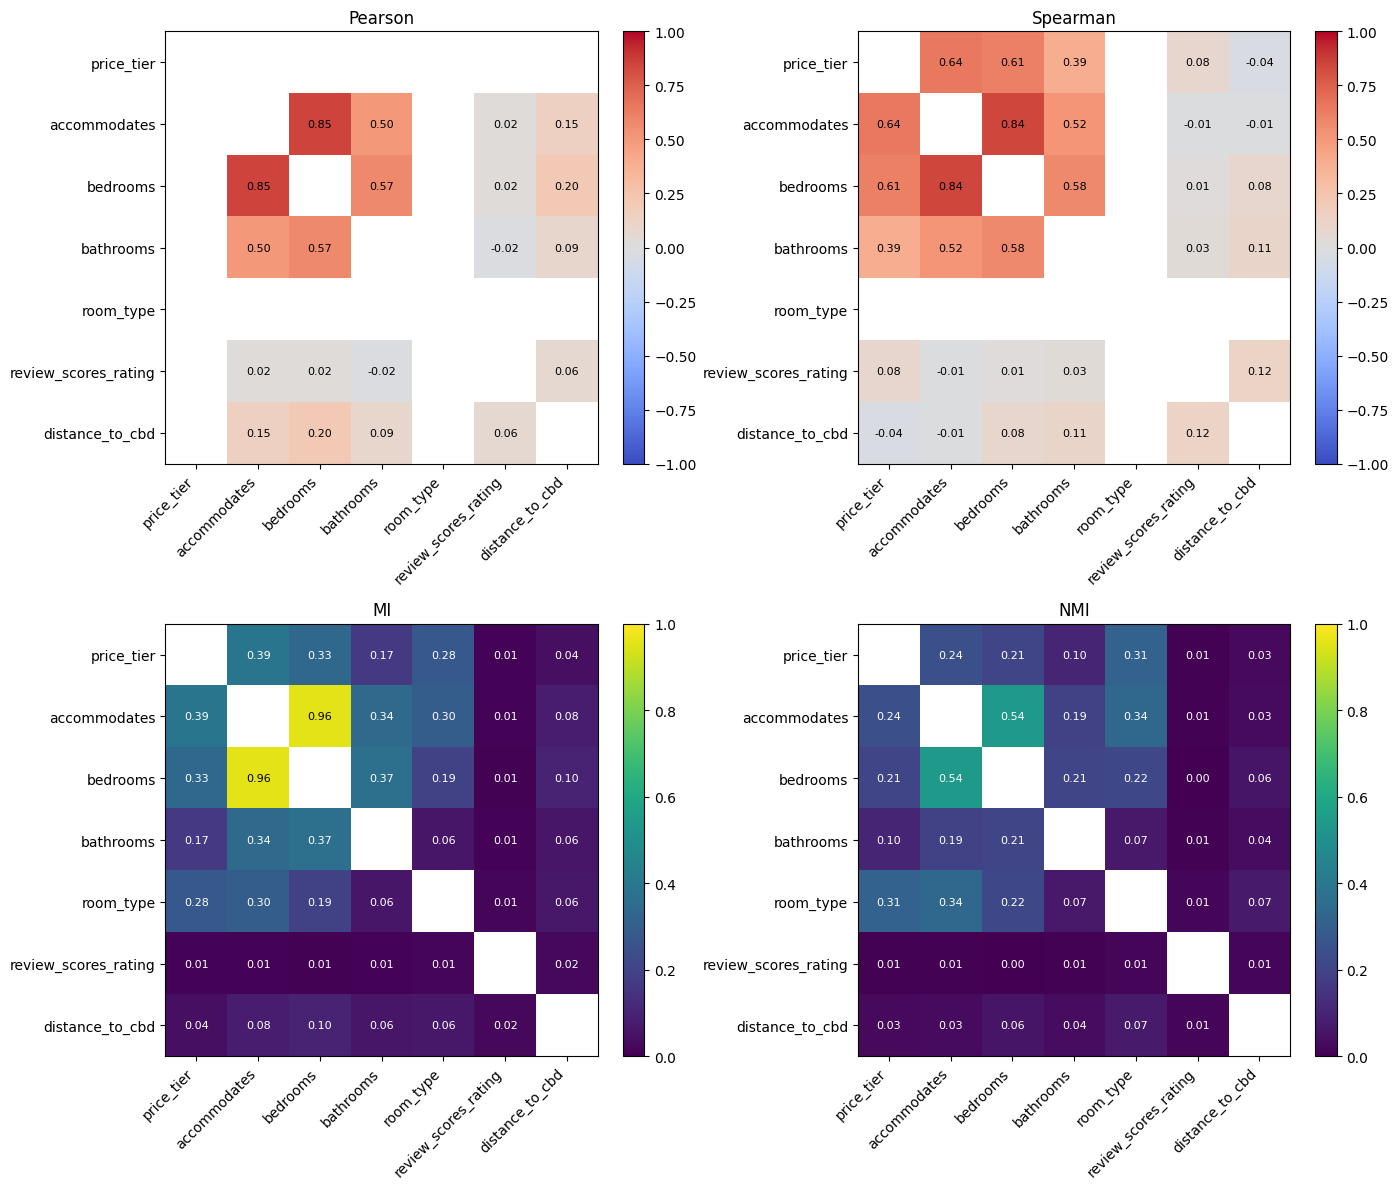

In [34]:
def matrix(col):
  temp = pd.DataFrame(np.nan, index = VARS, columns = VARS)
  vals = pd.to_numeric(result[col], errors = 'coerce')
  for i in range(len(result)):
    #Retrieve the first variable name in the row
    a = result.loc[i, 'var_1']
    #Retrieve the second variable name
    b = result.loc[i, 'var_2']
    #Retrieve the row's value
    v = vals[i]
    #Check if v is a real number or not and writes the value
    if not np.isnan(v):
      temp.loc[a, b] = v
      temp.loc[b, a] = v
  return temp
fig, axes = plt.subplots(2, 2, figsize = (14, 12))
settings = [(axes[0, 0], 'pear', 'coolwarm', -1, 1, 'Pearson'),
            (axes[0, 1], 'spear', 'coolwarm', -1, 1, 'Spearman'),
            (axes[1, 0], 'MI', 'viridis', 0, 1, 'MI'),
            (axes[1, 1], 'NMI', 'viridis', 0, 1, 'NMI')]
len_VARS = len(VARS)

for ax, col, cmap, vmin, vmax, title in settings:
  m = matrix(col)
  im = ax.imshow(m.values.astype(float), cmap = cmap, vmin = vmin, vmax = vmax)

  #Axis labels
  ax.set_xticks(range(len_VARS))
  ax.set_xticklabels(VARS, rotation = 45, ha = 'right')
  ax.set_yticks(range(len_VARS))
  ax.set_yticklabels(VARS)

  for i in range(len_VARS):
    for j in range(len_VARS):
      val = m.values[i, j]
      if not np.isnan(val):
        if col == 'NMI' or col =='MI' and val < 0.4:
          txt_color = 'white'
        else:
          txt_color = 'black'
        ax.text(j, i, f'{val:.2f}', ha = 'center', va = 'center', fontsize = 8, color = txt_color)

  ax.set_title(title)
  fig.colorbar(im, ax = ax, fraction = 0.046)
plt.tight_layout()
plt.savefig('correlation_heatmaps.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# Section: Supervised Learning & Evaluation
Primary: Ethan, Support: Minh

**What this section does:** trains two models (KNN and a Decision Tree) to predict each listing's price tier, tunes their settings with 5-fold stratified cross-validation, then tests them once on held-out listings and compares them to a baseline.

## 1. Load the data and pick the inputs
- Features = every cleaned column except the ID, the raw price (it would give the answer away) and text columns.
- `distance_to_cbd` is added using the same haversine formula as the correlation section.
- For unreviewed listings, `review_scores_rating` is set back to missing and filled after the split using the **training** median only, so nothing from the test set leaks into training.

In [35]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42                      # fixed seed so every run gives the same split and results
TIERS = ['low', 'medium', 'high']      # class order used in every report and chart

mdf = pd.read_csv('airbnb_cleaned.csv')

# Location feature: km from Melbourne CBD (same haversine formula as the correlation section,
# defined again here so this section doesn't depend on running the correlation cells)
def km_to_cbd(lat, lon, cbd_lat=-37.814, cbd_lon=144.963):
    lat1, lat2 = np.radians(lat), np.radians(cbd_lat)
    a = np.sin((lat1 - lat2) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(np.radians(lon - cbd_lon) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

mdf['distance_to_cbd'] = km_to_cbd(mdf['latitude'], mdf['longitude'])

# Unreviewed listings have no real rating: blank it now, fill it after the split (training median only)
mdf.loc[mdf['has_reviews'] == 0, 'review_scores_rating'] = np.nan

# Columns that must NOT be features
DROP = ['id',                       # just an identifier
        'price',                    # the target is built from price, so this would leak the answer
        'price_tier',               # the target itself
        'neighbourhood_cleansed',   # raw text (location is covered by lat/long/distance)
        'property_type']            # raw text (property type is covered by room_type)
X = mdf.drop(columns=[c for c in DROP if c in mdf.columns]).astype(float)   # one-hot columns load as True/False
y = mdf['price_tier']
ids = mdf['id']

# Sanity checks: no leakage, nothing unexpected missing
assert 'price' not in X.columns and 'price_tier' not in X.columns
assert X.drop(columns=['review_scores_rating']).isna().sum().sum() == 0, 'Unexpected missing values in features'

print('Number of features:', X.shape[1])
print(list(X.columns))

Number of features: 15
['latitude', 'longitude', 'accommodates', 'bedrooms', 'beds', 'number_of_reviews', 'review_scores_rating', 'reviews_per_month', 'bathrooms', 'has_reviews', 'room_type_Entire home/apt', 'room_type_Hotel room', 'room_type_Private room', 'room_type_Shared room', 'distance_to_cbd']


## 2. Split into training and test data

In [36]:
# How balanced is the target?
print('Class balance (full data):')
print(pd.concat([y.value_counts(), (y.value_counts(normalize=True) * 100).round(2)],
                axis=1, keys=['count', '%']))

# 80% train / 20% test, stratified so both keep the same tier shares
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X_train.copy(), X_test.copy()

# Fill unreviewed ratings with the TRAINING median (applied to both sets)
train_rating_median = X_train['review_scores_rating'].median()
X_train['review_scores_rating'] = X_train['review_scores_rating'].fillna(train_rating_median)
X_test['review_scores_rating'] = X_test['review_scores_rating'].fillna(train_rating_median)

# Sanity checks
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert set(id_train).isdisjoint(set(id_test)), 'A listing appears in both train and test'

print('\nTrain:', X_train.shape, '  Test:', X_test.shape)
print('Train tier %:', (y_train.value_counts(normalize=True) * 100).round(2).to_dict())
print('Test tier %: ', (y_test.value_counts(normalize=True) * 100).round(2).to_dict())
print('Training median rating used for unreviewed listings:', train_rating_median)
print('Each 5-fold CV validation fold holds about', len(X_train) // 5, 'listings,',
      'about', len(X_train) // 15, 'per tier')

Class balance (full data):
            count      %
price_tier              
medium       6406  33.41
low          6392  33.34
high         6377  33.26

Train: (15340, 15)   Test: (3835, 15)
Train tier %: {'medium': 33.41, 'low': 33.34, 'high': 33.25}
Test tier %:  {'medium': 33.4, 'low': 33.32, 'high': 33.27}
Training median rating used for unreviewed listings: 4.86
Each 5-fold CV validation fold holds about 3068 listings, about 1022 per tier


**Split justification:** tiers are terciles, so the classes are near-balanced (low 33.34%, medium 33.41%, high 33.26% in the full data). We still stratify so train and test keep exactly these shares (for example, low is 33.34% in train and 33.32% in test), which means a test score can't be skewed by an unlucky split. 80/20 leaves 3835 test listings, about 1278 per tier, enough for stable per-class precision and recall.

**Validation justification:** settings are tuned with 5-fold stratified CV on the 15340 training listings only. Each validation fold holds about 3068 listings (about 1022 per tier), large enough for a stable score, and every training listing is used for validation exactly once. The test set is not touched until the final evaluation.

**Tuning metric:** macro F1. All three tiers matter equally to the RQ, so F1 is averaged across tiers rather than letting one easy tier carry the score.

## 3. Tune KNN
Features are standardised inside the pipeline because KNN uses distances: without scaling, a column like `number_of_reviews` (hundreds) would drown out `bedrooms` (single digits). Putting the scaler inside the pipeline means it is re-fitted on each CV training fold only.

In [37]:
# Same 5 stratified folds are reused for both models so their CV scores are comparable
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_pipe = Pipeline([('scale', StandardScaler()),
                     ('knn', KNeighborsClassifier())])

# Every combination below is tried: 15 odd values of k (1, 3, ..., 29) x 2 weightings = 30 settings
# Odd k reduces tied votes; 30 settings keeps the run to a few minutes on ~15,000 training listings
knn_grid = {'knn__n_neighbors': list(range(1, 31, 2)),
            'knn__weights': ['uniform', 'distance']}

knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv, scoring='f1_macro',
                          return_train_score=True, n_jobs=-1)
knn_search.fit(X_train, y_train)

# Table of EVERY setting tried (rubric: report all values, not just the best)
knn_results = pd.DataFrame(knn_search.cv_results_)[
    ['param_knn__n_neighbors', 'param_knn__weights', 'mean_train_score', 'mean_test_score', 'std_test_score']]
knn_results.columns = ['k', 'weights', 'train_macro_f1', 'cv_macro_f1', 'cv_std']
knn_results = knn_results.round(4)
print(knn_results.to_string(index=False))
knn_results.to_csv('knn_cv_results.csv', index=False)

print('\nBest KNN setting:', knn_search.best_params_, '  CV macro F1:', round(knn_search.best_score_, 4))

 k  weights  train_macro_f1  cv_macro_f1  cv_std
 1  uniform          0.9996       0.6321  0.0041
 1 distance          0.9996       0.6321  0.0041
 3  uniform          0.8007       0.6451  0.0105
 3 distance          0.9996       0.6503  0.0119
 5  uniform          0.7615       0.6544  0.0105
 5 distance          0.9996       0.6668  0.0089
 7  uniform          0.7467       0.6621  0.0093
 7 distance          0.9996       0.6727  0.0092
 9  uniform          0.7345       0.6693  0.0110
 9 distance          0.9996       0.6779  0.0109
11  uniform          0.7270       0.6760  0.0120
11 distance          0.9996       0.6847  0.0114
13  uniform          0.7231       0.6792  0.0122
13 distance          0.9996       0.6865  0.0114
15  uniform          0.7186       0.6787  0.0093
15 distance          0.9996       0.6884  0.0107
17  uniform          0.7140       0.6783  0.0109
17 distance          0.9996       0.6871  0.0105
19  uniform          0.7129       0.6797  0.0075
19 distance         

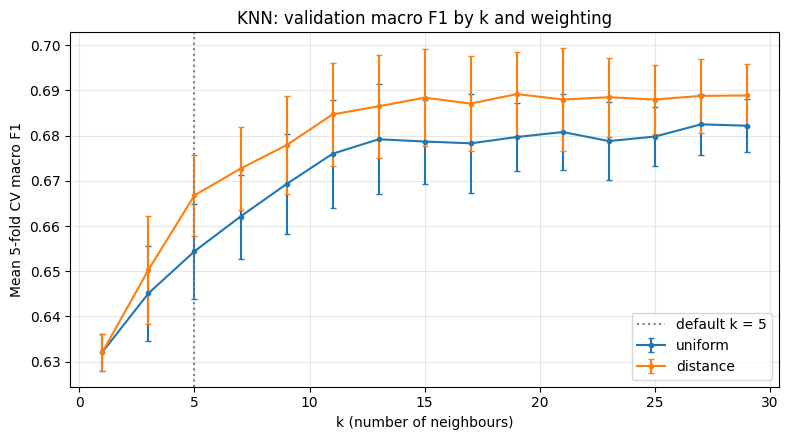

In [38]:
# Validation curve: how the CV score changes with k, for each weighting (error bars = std across the 5 folds)
fig, ax = plt.subplots(figsize=(8, 4.5))
for w in ['uniform', 'distance']:
    r = knn_results[knn_results.weights == w]
    ax.errorbar(r['k'], r['cv_macro_f1'], yerr=r['cv_std'], marker='o', ms=3, capsize=2, label=w)
ax.axvline(5, color='grey', ls=':', label='default k = 5')
ax.set_xlabel('k (number of neighbours)')
ax.set_ylabel('Mean 5-fold CV macro F1')
ax.set_title('KNN: validation macro F1 by k and weighting')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('knn_tuning.png', dpi=300)
plt.show()

## 4. Tune the Decision Tree
Trees don't use distances, so no scaling is needed.

In [39]:
# 19 depths + unlimited (None) x 5 leaf sizes = 100 settings
dt_grid = {'max_depth': list(range(2, 21)) + [None],
           'min_samples_leaf': [1, 5, 10, 20, 50]}

dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         dt_grid, cv=cv, scoring='f1_macro',
                         return_train_score=True, n_jobs=-1)
dt_search.fit(X_train, y_train)

# Table of EVERY setting tried
dt_results = pd.DataFrame(dt_search.cv_results_)[
    ['param_max_depth', 'param_min_samples_leaf', 'mean_train_score', 'mean_test_score', 'std_test_score']]
dt_results.columns = ['max_depth', 'min_samples_leaf', 'train_macro_f1', 'cv_macro_f1', 'cv_std']
dt_results['max_depth'] = dt_results['max_depth'].astype(object).fillna('None')   # show unlimited depth as 'None'
dt_results = dt_results.round(4)
print(dt_results.to_string(index=False))
dt_results.to_csv('dt_cv_results.csv', index=False)

print('\nBest Decision Tree setting:', dt_search.best_params_, '  CV macro F1:', round(dt_search.best_score_, 4))

max_depth  min_samples_leaf  train_macro_f1  cv_macro_f1  cv_std
        2                 1          0.6481       0.6481  0.0081
        2                 5          0.6481       0.6481  0.0081
        2                10          0.6481       0.6481  0.0081
        2                20          0.6481       0.6481  0.0081
        2                50          0.6481       0.6481  0.0081
        3                 1          0.6487       0.6473  0.0073
        3                 5          0.6487       0.6473  0.0073
        3                10          0.6487       0.6473  0.0073
        3                20          0.6487       0.6473  0.0073
        3                50          0.6496       0.6477  0.0073
        4                 1          0.6659       0.6596  0.0078
        4                 5          0.6658       0.6595  0.0079
        4                10          0.6656       0.6595  0.0079
        4                20          0.6655       0.6594  0.0078
        4                

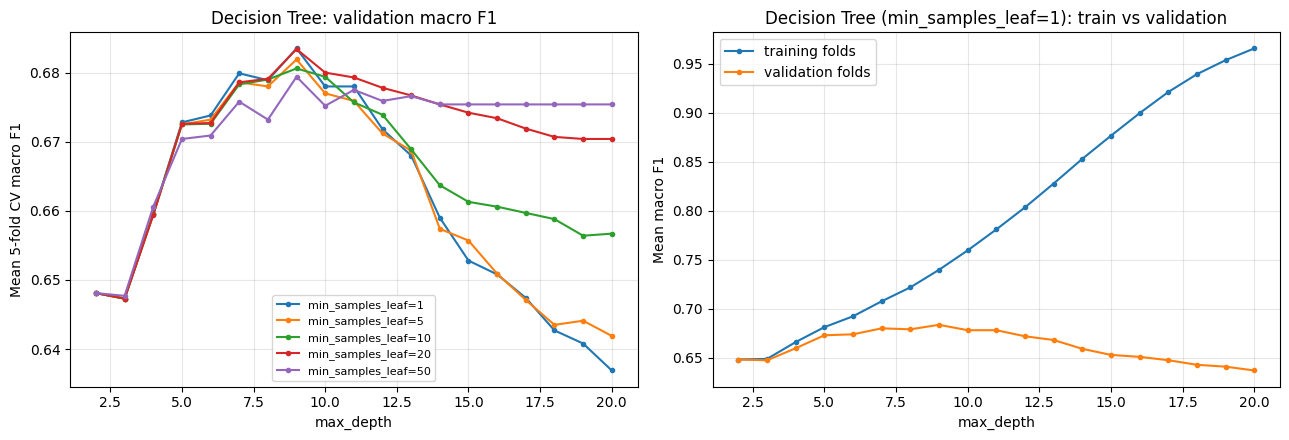

In [40]:
# Left: CV score by depth for each leaf size. Right: train vs CV score at leaf size 1 (shows overfitting as depth grows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for leaf in dt_grid['min_samples_leaf']:
    r = dt_results[(dt_results.min_samples_leaf == leaf) & (dt_results.max_depth != 'None')]
    axes[0].plot(r['max_depth'].astype(int), r['cv_macro_f1'], marker='o', ms=3, label=f'min_samples_leaf={leaf}')
axes[0].set_xlabel('max_depth'); axes[0].set_ylabel('Mean 5-fold CV macro F1')
axes[0].set_title('Decision Tree: validation macro F1'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

r1 = dt_results[(dt_results.min_samples_leaf == 1) & (dt_results.max_depth != 'None')]
axes[1].plot(r1['max_depth'].astype(int), r1['train_macro_f1'], marker='o', ms=3, label='training folds')
axes[1].plot(r1['max_depth'].astype(int), r1['cv_macro_f1'], marker='o', ms=3, label='validation folds')
axes[1].set_xlabel('max_depth'); axes[1].set_ylabel('Mean macro F1')
axes[1].set_title('Decision Tree (min_samples_leaf=1): train vs validation'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('dt_tuning.png', dpi=300)
plt.show()

## 5. Default vs chosen settings
For each setting, the "effect" compares the best model with the same model where **only that one setting** is put back to its sklearn default. Values come straight from the CV tables above, so they can be quoted in the report.

In [41]:
def cv_score(results, **params):
    """Look up the CV (and train) macro F1 for one exact setting in a results table."""
    row = results
    for k, v in params.items():
        row = row[row[k].astype(str) == str(v)]
    assert len(row) == 1, f'setting not found: {params}'
    return row['cv_macro_f1'].iloc[0], row['train_macro_f1'].iloc[0]

kb = knn_search.best_params_
db = dt_search.best_params_
best_knn_cv, best_knn_tr = cv_score(knn_results, k=kb['knn__n_neighbors'], weights=kb['knn__weights'])
best_dt_cv, best_dt_tr = cv_score(dt_results, max_depth=str(db['max_depth']), min_samples_leaf=db['min_samples_leaf'])

# (model, hyperparameter, default value, chosen value, CV/train score with ONLY this setting at default)
rows = [
    ('KNN', 'n_neighbors', 5, kb['knn__n_neighbors'],
     cv_score(knn_results, k=5, weights=kb['knn__weights']), (best_knn_cv, best_knn_tr)),
    ('KNN', 'weights', 'uniform', kb['knn__weights'],
     cv_score(knn_results, k=kb['knn__n_neighbors'], weights='uniform'), (best_knn_cv, best_knn_tr)),
    ('Decision Tree', 'max_depth', 'None', db['max_depth'],
     cv_score(dt_results, max_depth='None', min_samples_leaf=db['min_samples_leaf']), (best_dt_cv, best_dt_tr)),
    ('Decision Tree', 'min_samples_leaf', 1, db['min_samples_leaf'],
     cv_score(dt_results, max_depth=str(db['max_depth']), min_samples_leaf=1), (best_dt_cv, best_dt_tr)),
]
effect = pd.DataFrame([{
    'model': m, 'hyperparameter': h, 'default': d, 'chosen': c,
    'changed?': 'yes' if str(d) != str(c) else 'no (default was best)',
    'CV F1 at default': dflt[0], 'CV F1 chosen': best[0],
    'effect on CV F1': round(best[0] - dflt[0], 4),
    'train F1 at default': dflt[1], 'train F1 chosen': best[1],
} for m, h, d, c, dflt, best in rows])
print(effect.to_string(index=False))
effect.to_csv('hyperparameter_effects.csv', index=False)

# Also: fully default models vs fully tuned models
print('\nFully default KNN (k=5, uniform):        CV F1', cv_score(knn_results, k=5, weights='uniform')[0])
print('Fully default DT (None depth, leaf=1):   CV F1', cv_score(dt_results, max_depth='None', min_samples_leaf=1)[0],
      ' | train F1', cv_score(dt_results, max_depth='None', min_samples_leaf=1)[1])

        model   hyperparameter default   chosen              changed?  CV F1 at default  CV F1 chosen  effect on CV F1  train F1 at default  train F1 chosen
          KNN      n_neighbors       5       19                   yes            0.6668        0.6892           0.0224               0.9996           0.9996
          KNN          weights uniform distance                   yes            0.6797        0.6892           0.0095               0.7129           0.9996
Decision Tree        max_depth    None        9                   yes            0.6274        0.6835           0.0561               0.9996           0.7396
Decision Tree min_samples_leaf       1        1 no (default was best)            0.6835        0.6835           0.0000               0.7396           0.7396

Fully default KNN (k=5, uniform):        CV F1 0.6544
Fully default DT (None depth, leaf=1):   CV F1 0.6274  | train F1 0.9996


**Write-up:**
- **KNN `n_neighbors`:** default 5, chosen 19. CV macro F1 rises from 0.6668 to 0.6892 (+0.022). k = 1 scores only 0.6321 because it copies a single neighbour; gains flatten after about k = 15 (all values from 15 to 29 sit between 0.687 and 0.689).
- **KNN `weights`:** default uniform, chosen distance. At k = 19, CV macro F1 rises from 0.6797 to 0.6892 (+0.0095), so closer listings counting more helps a little.
- **DT `max_depth`:** default None (grows until every leaf is pure), chosen 9. CV macro F1 rises from 0.6274 to 0.6835 (+0.056). At default the tree scores 0.9996 on training folds but only 0.6274 on validation: it memorises training listings. Past depth 9, training F1 keeps climbing (0.74 to 0.97 at depth 20) while validation F1 falls (0.68 to 0.64).
- **DT `min_samples_leaf`:** default 1, and 1 was also best at depth 9 (0.6835), so it was left unchanged. Larger leaves mainly help an unlimited-depth tree (0.6274 at leaf 1 vs 0.6754 at leaf 50), which depth 9 already controls.
- **Fully default vs tuned:** KNN 0.6544 to 0.6892, Decision Tree 0.6274 to 0.6835.

**Reading the train scores:** with `weights='distance'` KNN scores about 1.0 on its own training data (each point is its own nearest neighbour at distance 0), so only the CV score is meaningful for that setting.

**Why these hyperparameters:** k and weighting control how local each KNN vote is; depth and leaf size control tree complexity, the main source of overfitting. The charts show both visibly move the score, so they genuinely influence behaviour.

## 6. Test both models against a baseline
Each model is refitted on the full training set with its best setting (GridSearchCV does this automatically), then evaluated **once** on the untouched 20% test set.

In [42]:
best_knn = knn_search.best_estimator_
best_dt = dt_search.best_estimator_
# Baseline: always predict the most common training tier (the floor a useful model must beat)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

models = {'Baseline (majority class)': baseline, 'KNN': best_knn, 'Decision Tree': best_dt}
preds, summary = {}, []
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    # Per-class precision / recall / F1 for every model (rubric requirement)
    print(f'===== {name} =====')
    print(classification_report(y_test, p, labels=TIERS, digits=3, zero_division=0))
    summary.append({'model': name,
                    'accuracy': accuracy_score(y_test, p),
                    'macro_f1': f1_score(y_test, p, average='macro', labels=TIERS, zero_division=0)})

# Absolute improvement over the baseline
summary = pd.DataFrame(summary).round(4)
base = summary.iloc[0]
summary['accuracy_gain_vs_baseline'] = (summary['accuracy'] - base['accuracy']).round(4)
summary['macro_f1_gain_vs_baseline'] = (summary['macro_f1'] - base['macro_f1']).round(4)
print(summary.to_string(index=False))
summary.to_csv('model_summary.csv', index=False)

# Save every test listing with its features, true tier and both predictions
# (used to pick a specific "hard case" listing by ID in Feature Selection interpretation)
test_out = X_test.copy()
test_out.insert(0, 'id', id_test.values)
test_out['true_tier'] = y_test.values
test_out['knn_pred'] = preds['KNN']
test_out['dt_pred'] = preds['Decision Tree']
test_out.to_csv('test_predictions.csv', index=False)
print('\nTest listings where both models are wrong:',
      ((test_out.knn_pred != test_out.true_tier) & (test_out.dt_pred != test_out.true_tier)).sum())

===== Baseline (majority class) =====
              precision    recall  f1-score   support

         low      0.000     0.000     0.000      1278
      medium      0.334     1.000     0.501      1281
        high      0.000     0.000     0.000      1276

    accuracy                          0.334      3835
   macro avg      0.111     0.333     0.167      3835
weighted avg      0.112     0.334     0.167      3835

===== KNN =====
              precision    recall  f1-score   support

         low      0.787     0.762     0.774      1278
      medium      0.587     0.626     0.606      1281
        high      0.732     0.705     0.718      1276

    accuracy                          0.698      3835
   macro avg      0.702     0.698     0.699      3835
weighted avg      0.702     0.698     0.699      3835

===== Decision Tree =====
              precision    recall  f1-score   support

         low      0.828     0.727     0.774      1278
      medium      0.558     0.666     0.607      

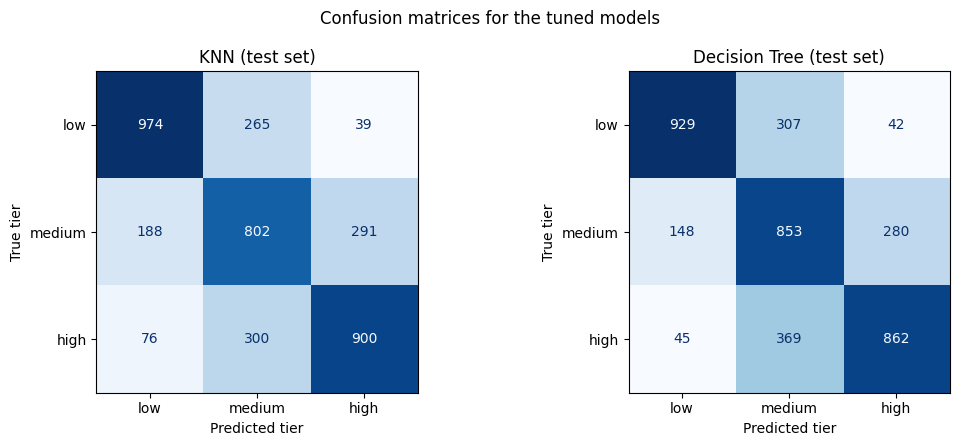

In [43]:
# Confusion matrices: rows = true tier, columns = predicted tier
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ['KNN', 'Decision Tree']):
    cm = confusion_matrix(y_test, preds[name], labels=TIERS)
    ConfusionMatrixDisplay(cm, display_labels=TIERS).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name} (test set)')
    ax.set_xlabel('Predicted tier'); ax.set_ylabel('True tier')
fig.suptitle('Confusion matrices for the tuned models')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()

**Metric justification:** the RQ asks whether listings can be placed in the right tier, so every tier matters equally. Accuracy alone hides which tiers get confused. Per-class **precision** answers "when the model says high, how often is it right?", **recall** answers "of the truly high listings, how many did it find?", and **F1** combines both. `medium` sits between the other two tiers, so it can be mistaken in both directions: it has the lowest F1 for both models (KNN 0.606, DT 0.607), against 0.774 for `low` and 0.718 / 0.701 for `high`.

**Baseline:** the majority-class baseline predicts `medium` for every listing, scoring 33.4% accuracy and macro F1 0.167. KNN improves accuracy by 36.4 percentage points (to 69.8%) and macro F1 by 0.533 (to 0.699); the Decision Tree improves accuracy by 35.5 points (to 68.9%) and macro F1 by 0.527 (to 0.694).

## 7. How confident are the scores?
Resample the test set with replacement 1,000 times and recompute macro F1 each time. The same resamples are used for both models, so we can also get a CI for the **difference** between them (a fairer test than checking whether two separate CIs overlap).

In [44]:
rng = np.random.default_rng(RANDOM_STATE)
y_true = y_test.to_numpy()
p_knn, p_dt = preds['KNN'], preds['Decision Tree']
n, B = len(y_true), 1000

f1_knn, f1_dt = [], []
for _ in range(B):
    idx = rng.integers(0, n, n)     # one bootstrap sample of test listings (same for both models)
    f1_knn.append(f1_score(y_true[idx], p_knn[idx], average='macro', labels=TIERS, zero_division=0))
    f1_dt.append(f1_score(y_true[idx], p_dt[idx], average='macro', labels=TIERS, zero_division=0))
f1_knn, f1_dt = np.array(f1_knn), np.array(f1_dt)

def ci(a):
    """95% percentile interval."""
    return np.percentile(a, [2.5, 97.5]).round(4)

print(f"KNN           test macro F1 = {f1_score(y_true, p_knn, average='macro'):.4f}, 95% CI {ci(f1_knn)}")
print(f"Decision Tree test macro F1 = {f1_score(y_true, p_dt, average='macro'):.4f}, 95% CI {ci(f1_dt)}")
diff_ci = ci(f1_knn - f1_dt)
print(f'Difference (KNN - DT): 95% CI {diff_ci}  ->',
      'includes 0, so no clear winner' if diff_ci[0] <= 0 <= diff_ci[1] else 'excludes 0, so the gap is unlikely to be chance')

KNN           test macro F1 = 0.6994, 95% CI [0.6856 0.7142]
Decision Tree test macro F1 = 0.6940, 95% CI [0.6797 0.7091]
Difference (KNN - DT): 95% CI [-0.0071  0.0185]  -> includes 0, so no clear winner


**Why bootstrap:** we have one fixed test set of 3,835 listings. Resampling it 1,000 times shows how much macro F1 would vary on a different sample of Melbourne listings, without retraining: KNN 0.699 (95% CI 0.686 to 0.714), Decision Tree 0.694 (0.680 to 0.709). A binomial (normal-approximation) interval only works for accuracy, not macro F1, and re-running CV would measure tuning variance on training data rather than uncertainty in the final test score. The paired difference (KNN minus DT) has a 95% CI of -0.007 to 0.019, which includes 0, so neither model is clearly better.

## 8. Which features matter most
- **Decision Tree:** built-in (Gini) importances. This is the **embedded** feature selection method, saved for the Feature Selection section.
- **KNN:** no built-in importances, so we use permutation importance: shuffle one feature in the test set and measure how much macro F1 drops.

Decision Tree importances (top 10):
room_type_Entire home/apt    0.4093
bedrooms                     0.2270
accommodates                 0.0899
distance_to_cbd              0.0592
longitude                    0.0479
latitude                     0.0460
reviews_per_month            0.0453
bathrooms                    0.0302
review_scores_rating         0.0171
number_of_reviews            0.0154
dtype: float64
Top 3: ['room_type_Entire home/apt', 'bedrooms', 'accommodates']

KNN permutation importance, mean drop in macro F1 (top 10):
bedrooms                  0.0439
room_type_Private room    0.0383
distance_to_cbd           0.0349
longitude                 0.0326
bathrooms                 0.0301
accommodates              0.0294
reviews_per_month         0.0260
latitude                  0.0257
review_scores_rating      0.0196
beds                      0.0176
dtype: float64


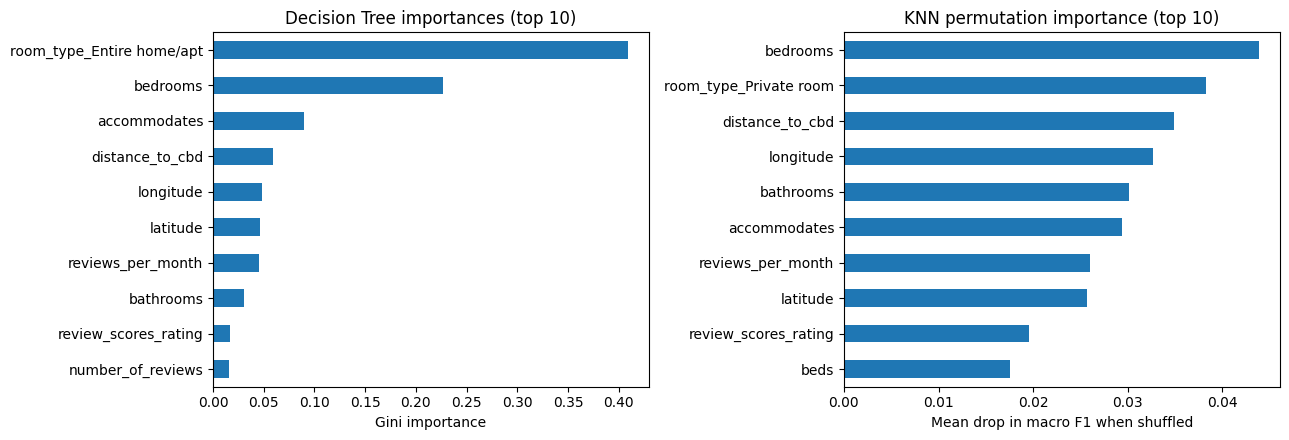

In [45]:
# Decision Tree importances (sum to 1 across features)
dt_imp = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)
dt_imp.to_csv('dt_feature_importances.csv', header=['importance'])
print('Decision Tree importances (top 10):')
print(dt_imp.head(10).round(4))
print('Top 3:', list(dt_imp.index[:3]))

# KNN permutation importance (5 shuffles per feature, averaged)
perm = permutation_importance(best_knn, X_test, y_test, scoring='f1_macro',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
knn_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
knn_imp.to_csv('knn_permutation_importances.csv', header=['mean_f1_drop'])
print('\nKNN permutation importance, mean drop in macro F1 (top 10):')
print(knn_imp.head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dt_imp.head(10)[::-1].plot.barh(ax=axes[0])
axes[0].set_title('Decision Tree importances (top 10)'); axes[0].set_xlabel('Gini importance')
knn_imp.head(10)[::-1].plot.barh(ax=axes[1])
axes[1].set_title('KNN permutation importance (top 10)'); axes[1].set_xlabel('Mean drop in macro F1 when shuffled')
plt.tight_layout()
plt.savefig('feature_influence.png', dpi=300)
plt.show()

**Interpretation:**
- **Reading permutation importance:** a value near 0 (or slightly negative) means shuffling that feature made no real difference, i.e. KNN barely relies on it.
- **Feature influence:** both models lean most on size and room type. The tree's top 3 are `room_type_Entire home/apt` (0.409), `bedrooms` (0.227) and `accommodates` (0.090); KNN's biggest drops come from shuffling `bedrooms` (0.044) and `room_type_Private room` (0.038). This matches the correlation section, where `accommodates` (Spearman 0.643) and `bedrooms` (0.614) have the strongest association with `price_tier`. Location matters more to KNN (`distance_to_cbd` 0.035, 3rd) than its weak correlation with tier (Spearman -0.038) suggests, likely because the effect of distance isn't a simple straight line. Review features rank low in both models, in line with `review_scores_rating` vs `price_tier` (Spearman 0.081). These are associations, not causes.
- **Model behaviour:** most errors are between neighbouring tiers. KNN confuses `high` with `medium` 300 times but with `low` only 76; the tree 369 vs 45. Both models are wrong on the same 847 test listings, suggesting those listings are genuinely ambiguous given these features rather than a quirk of one model.
- **Limitations:** tiers are cut at fixed prices (about $188 and $307), so listings just either side of a cut are near-identical but labelled differently. KNN weighs every scaled feature equally, so weak features add noise to its distances. A single tree is unstable to small changes in the data. `room_type` is one-hot, so its importance is split across 4 columns. `accommodates`, `bedrooms` and `beds` are strongly correlated and can share importance. Imputation medians and tier cut-offs were computed on the full dataset before the split (a small leak, accepted for simplicity). No amenity, seasonality or host features.
- **RQ:** listing size, room type and location can place Melbourne listings in the right price tier about 70% of the time (macro F1 about 0.70 vs 0.17 for the baseline), with capacity and room type the most influential attributes and review performance contributing little.

# Section: Feature Selection
Primary: Minh, Support: Ethan

- **Filter method :** Mutual information with `price_tier`, on the same feature set used for modelling.
- **Embedded method:** Decision Tree importances from the tuned tree in the Supervised Learning section (`dt_feature_importances.csv`).

## 1. Filter method: Mutual information between each feature and `price_tier`

-The filter method looks at each of the 15 features separately to see how useful they are for predicting `price_tier`. We measure this using mutual information (MI), where a higher MI means the feature gives us more information about the price tier.

-Since MI needs categories, we first group the features:
  - Yes/no features (`room_type` columns and `has_reviews`): Already categorical, so we leave them as they are.
  - Count features: Each value gets its own group, while very large values are grouped together (`accommodates` 10+, `bedrooms` 5+, `bathrooms` 4+, `beds` 6+).
  - Continuous features: Split into 10 equal-frequency groups, with roughly the same number of listings in each.

-We use MI instead of NMI to rank the features because NMI can make yes/no features seem more important than they really are. For example, `room_type_Shared room` has an MI of only 0.0155, but its NMI is 0.1818.

In [46]:
#Caps for count features
F_CAPS =  {'accommodates': 10, 'bedrooms': 5, 'bathrooms': 4, 'beds': 6}
N_F_BINS = 10
def f_discretise(t, n, other_s=None):
  #Turn one feature into categories, learning any bin edges from the data
  if t.nunique() <= 2:
    t_cat = t.astype(int).astype(str)
    if other_s is None:
      return t_cat, None
    else:
      return t_cat, other_s.astype(int).astype(str)
  elif n in F_CAPS:
    #Count features: each value is a category
    cap = F_CAPS[n]
    t_cat = t.clip(upper = cap).astype(str)
    if other_s is None:
      return t_cat, None
    else:
      return t_cat, other_s.clip(upper = cap).astype(str)
  else:
  #Continuous features: equal-frequency bins
    _, edges = pd.qcut(t, q = N_F_BINS, retbins = True, duplicates = 'drop')
    edges[0] = -np.inf
    edges[-1] = np.inf
    t_cat = pd.cut(t, bins = edges, labels = False, include_lowest = True).astype(str)
    if other_s is None:
      return t_cat, None
    else:
      return t_cat, pd.cut(other_s, bins = edges, labels = False, include_lowest = True).astype(str)


In [47]:
y_tr = y_train.astype(str)
fs_rows = []
for f in X_train.columns:
  xd, _ =f_discretise(X_train[f], f)
  fs_rows.append(
      {'feature': f, 'categories': xd.nunique(), 'MI': mutual_info(xd, y_tr), 'NMI' : norm_MI(xd, y_tr)}
  )

In [48]:
filter_scores = pd.DataFrame(fs_rows).set_index('feature').sort_values('MI', ascending=False)
filter_scores['MI_rank'] = range(1, len(filter_scores) + 1)
print('Filter method (MI with price_tier, training data):')
print(filter_scores.round(4).to_string())

Filter method (MI with price_tier, training data):
                           categories      MI     NMI  MI_rank
feature                                                       
accommodates                       10  0.3825  0.2413        1
bedrooms                            5  0.3336  0.2105        2
beds                                7  0.2708  0.1708        3
room_type_Entire home/apt           2  0.2676  0.3325        4
room_type_Private room              2  0.2489  0.3178        5
bathrooms                           9  0.1619  0.1021        6
distance_to_cbd                    10  0.0420  0.0265        7
reviews_per_month                   9  0.0374  0.0236        8
latitude                           10  0.0360  0.0227        9
longitude                          10  0.0358  0.0226       10
number_of_reviews                   9  0.0226  0.0142       11
review_scores_rating                9  0.0190  0.0120       12
room_type_Shared room               2  0.0155  0.1818       13
has_

## 2. Embedded method and comparison

-The embedded method uses Gini importance from the tuned Decision Tree (`max_depth = 9`) to rank the 15 features. Features used near the top usually have higher importance because they affect more listings. All importances add up to 1.

-We then put the rankings from both methods side by side:
  - `MI_rank` / `DT_rank`: Show where each feature ranks in the filter and embedded methods (1 = most important).
  - `rank_gap = MI_rank - DT_rank`: A positive value means the tree ranks the feature higher, while a negative value means MI ranks it higher.

-Finally, we look at the top 3 features from each method to see which ones appear in both lists and where the methods disagree.

In [49]:
em_scores = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)

#Put both rankings side by side
compare_fs = filter_scores[['MI', 'NMI', 'MI_rank']].copy()
compare_fs['DT_importance'] = em_scores

#Rank by tree importance
compare_fs['DT_rank'] = em_scores.rank(ascending = False, method = 'min').astype(int)

#Rank gap: positve = the tree rates the feature higher, negative = MI rate it higher
compare_fs['rank_gap'] = compare_fs['MI_rank'] - compare_fs['DT_rank']
print(compare_fs.round(4).to_string())
compare_fs.round(4).to_csv('feature_selection_comparision.csv')

                               MI     NMI  MI_rank  DT_importance  DT_rank  rank_gap
feature                                                                             
accommodates               0.3825  0.2413        1         0.0899        3        -2
bedrooms                   0.3336  0.2105        2         0.2270        2         0
beds                       0.2708  0.1708        3         0.0042       12        -9
room_type_Entire home/apt  0.2676  0.3325        4         0.4093        1         3
room_type_Private room     0.2489  0.3178        5         0.0000       15       -10
bathrooms                  0.1619  0.1021        6         0.0302        8        -2
distance_to_cbd            0.0420  0.0265        7         0.0592        4         3
reviews_per_month          0.0374  0.0236        8         0.0453        7         1
latitude                   0.0360  0.0227        9         0.0460        6         3
longitude                  0.0358  0.0226       10         0.0479

In [50]:
#Top 3 features from each method
top_filter = list(filter_scores.index[:3])
top_em = list(em_scores.index[:3])
print('Top 3 (filter, MI):', top_filter)
print('Top 3 (embedded, DT):', top_em)
print('In both top 3: ',[bt for bt in top_filter if bt in top_em])
print('Only in filter top 3', [f for f in top_filter if f not in top_em])
print('Only in embedded top 3', [e for e in top_em if e not in top_filter])

Top 3 (filter, MI): ['accommodates', 'bedrooms', 'beds']
Top 3 (embedded, DT): ['room_type_Entire home/apt', 'bedrooms', 'accommodates']
In both top 3:  ['accommodates', 'bedrooms']
Only in filter top 3 ['beds']
Only in embedded top 3 ['room_type_Entire home/apt']


## 3. Hard case: listing where the two top features disagree



-For each test listing, we look at what price tier would be suggested by the top feature from each method:

- Filter method: `accommodates`

- Embedded method: `room_type_Entire home/apt`

-We then keep only the listings where both models made the wrong prediction and the two features suggest different price tiers. We then choose `accommodates` as it is furthest from the training median of 4. This gives us a clear example where the two feature selection methods disagree.

In [51]:
#filter method's top feature
f_top = filter_scores.index[0]
#embedded method's top feature
e_top = em_scores.index[0]

In [52]:
def implied_tier(feature):
    tr_cat, te_cat = f_discretise(X_train[feature], feature, X_test[feature])
    majority = y_tr.groupby(tr_cat).agg(lambda s: s.value_counts().idxmax())
    return te_cat.map(majority).values

In [53]:
hc = pd.read_csv('test_predictions.csv')
hc['price'] = hc['id'].map(mdf.set_index('id')['price'])
hc['filter_says'] = implied_tier(f_top)
hc['embedded_says'] = implied_tier(e_top)

In [54]:
cands = hc[(hc['knn_pred'] != hc['true_tier']) & (hc['dt_pred'] != hc['true_tier'])
           & (hc['filter_says'] != hc['embedded_says'])]
chosen = cands.loc[(cands[f_top] - X_train[f_top].median()).abs().idxmax()]

In [55]:
print(f'Filter top: {f_top} | Embedded top: {e_top} | Candidate: {len(cands)}')
print(chosen.to_string())
print(f'{f_top} in training data: median {X_train[f_top].median():.2f}')

Filter top: accommodates | Embedded top: room_type_Entire home/apt | Candidate: 567
id                              2571693
latitude                     -37.767418
longitude                    145.674079
accommodates                        8.0
bedrooms                            2.0
beds                                2.0
number_of_reviews                 196.0
review_scores_rating               4.87
reviews_per_month                  1.32
bathrooms                           2.0
has_reviews                         1.0
room_type_Entire home/apt           0.0
room_type_Hotel room                0.0
room_type_Private room              1.0
room_type_Shared room               0.0
distance_to_cbd               62.698286
true_tier                        medium
knn_pred                            low
dt_pred                             low
price                             252.7
filter_says                        high
embedded_says                       low
accommodates in training data: media